In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv("churn.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (7043, 21)


In [4]:
df_clean = df.copy()

In [5]:
missing_values = df_clean.isnull().sum()

print(missing_values)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
missing_percentage = (
    df_clean.isnull().sum() / len(df_clean)
) * 100

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

print(missing_report[missing_report['Missing Values'] > 0])

Empty DataFrame
Columns: [Missing Values, Missing Percentage]
Index: []


In [7]:
print("Duplicate records:", df_clean.duplicated().sum())

Duplicate records: 0


In [8]:
print("Duplicate Customer IDs:", df_clean['customerID'].duplicated().sum())
df_clean = df_clean.drop_duplicates(
    subset='customerID',
    keep='first'
)

Duplicate Customer IDs: 0


In [9]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [10]:
print(df_clean['TotalCharges'].head(10))

print("\nData type:")
print(df_clean['TotalCharges'].dtype)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

Data type:
str


In [11]:
df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'],
    errors='coerce'
)

In [12]:
print(df_clean['TotalCharges'].dtype)

print("Missing TotalCharges:",
      df_clean['TotalCharges'].isnull().sum())

float64
Missing TotalCharges: 11


In [13]:
blank_charges = df_clean[
    df_clean['TotalCharges'].isnull()
]

print(blank_charges[
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']
])

      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           NaN
753   3115-CZMZD       0           20.25           NaN
936   5709-LVOEQ       0           80.85           NaN
1082  4367-NUYAO       0           25.75           NaN
1340  1371-DWPAZ       0           56.05           NaN
3331  7644-OMVMY       0           19.85           NaN
3826  3213-VVOLG       0           25.35           NaN
4380  2520-SGTTA       0           20.00           NaN
5218  2923-ARZLG       0           19.70           NaN
6670  4075-WKNIU       0           73.35           NaN
6754  2775-SEFEE       0           61.90           NaN


In [14]:
print(blank_charges['tenure'].value_counts())

tenure
0    11
Name: count, dtype: int64


In [15]:
df_clean.loc[
    df_clean['TotalCharges'].isnull() &
    (df_clean['tenure'] == 0),
    'TotalCharges'
] = 0

In [16]:
print("Remaining missing values:",
      df_clean['TotalCharges'].isnull().sum())

Remaining missing values: 0


In [19]:
categorical_columns = df_clean.select_dtypes(include='object').columns

print(categorical_columns)

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')


C:\Users\HP\AppData\Local\Temp\ipykernel_3192\3793305945.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df_clean.select_dtypes(include='object').columns


In [20]:
for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(df_clean[col].unique())


Column: customerID
<StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str

Column: gender
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

Column: Partner
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Column: Dependents
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Column: PhoneService
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Column: MultipleLines
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

Column: InternetService
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

Column: OnlineSecurity
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

Column: OnlineBackup
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: s

In [22]:
for col in categorical_columns:
    df_clean[col] = df_clean[col].str.strip()

In [23]:
for col in categorical_columns:
    print(f"\n{col}:")
    print(df_clean[col].unique())


customerID:
<StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str

gender:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

Partner:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Dependents:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

PhoneService:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

MultipleLines:
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

InternetService:
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

OnlineSecurity:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

OnlineBackup:
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

DeviceProtection:
<StringArray>
['No', 'Yes', 'No internet 

In [24]:
numerical_columns = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

df_clean[numerical_columns].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


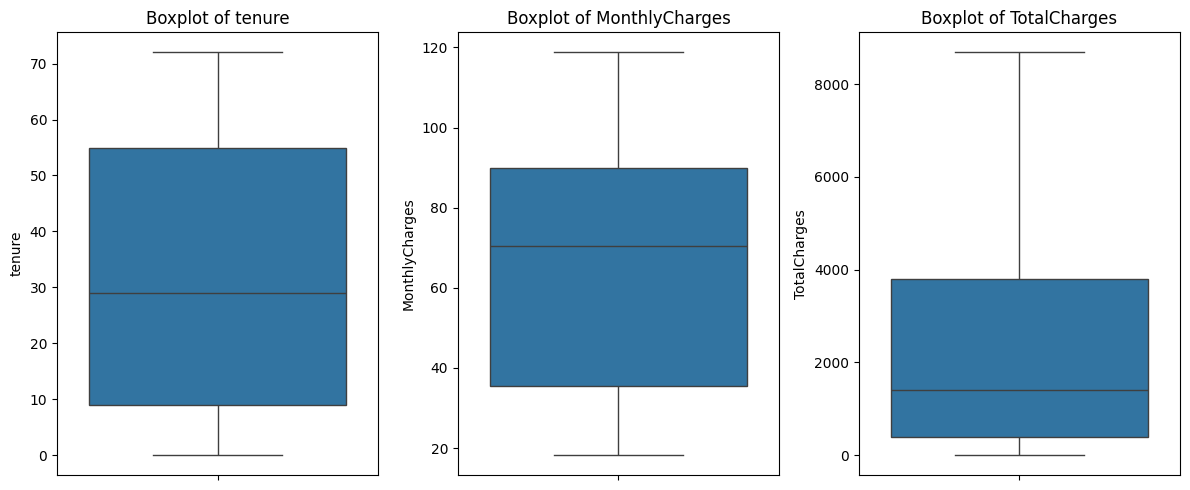

In [25]:
plt.figure(figsize=(12, 5))

for i, col in enumerate(numerical_columns, 1):

    plt.subplot(1, 3, i)

    sns.boxplot(y=df_clean[col])

    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [26]:
outlier_report = []

for col in numerical_columns:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_limit) |
        (df_clean[col] > upper_limit)
    ]

    outlier_report.append({
        'Column': col,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers)
    })

outlier_df = pd.DataFrame(outlier_report)

print(outlier_df)

           Column  Lower Limit  Upper Limit  Outlier Count
0          tenure      -60.000      124.000              0
1  MonthlyCharges      -46.025      171.375              0
2    TotalCharges    -4683.525     8868.675              0


In [27]:
expected_categories = {
    'gender': ['Male', 'Female'],
    'Partner': ['Yes', 'No'],
    'Dependents': ['Yes', 'No'],
    'PhoneService': ['Yes', 'No'],
    'PaperlessBilling': ['Yes', 'No'],
    'Churn': ['Yes', 'No']
}

for col, expected in expected_categories.items():

    actual = set(df_clean[col].dropna().unique())

    unexpected = actual - set(expected)

    print(f"\n{col}")
    print("Actual:", actual)
    print("Unexpected:", unexpected)


gender
Actual: {'Male', 'Female'}
Unexpected: set()

Partner
Actual: {'No', 'Yes'}
Unexpected: set()

Dependents
Actual: {'No', 'Yes'}
Unexpected: set()

PhoneService
Actual: {'No', 'Yes'}
Unexpected: set()

PaperlessBilling
Actual: {'No', 'Yes'}
Unexpected: set()

Churn
Actual: {'No', 'Yes'}
Unexpected: set()


In [28]:
columns_to_check = [
    'InternetService',
    'Contract',
    'PaymentMethod',
    'OnlineSecurity',
    'TechSupport'
]

for col in columns_to_check:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False))


InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PaymentMethod:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

TechSupport:
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64


In [29]:
df_clean['customerID'] = df_clean['customerID'].astype('string')

df_clean['SeniorCitizen'] = df_clean['SeniorCitizen'].astype('int64')

df_clean['tenure'] = df_clean['tenure'].astype('int64')

df_clean['MonthlyCharges'] = pd.to_numeric(
    df_clean['MonthlyCharges'],
    errors='raise'
)

df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'],
    errors='raise'
)

In [30]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   string 
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen